# T-PRIME baseline vs CMAT: synthetic validation and real-world (OOD) X410 captures

* **Baseline**: T-PRIME transformer trained on pure synthetic waveforms + AWGN (5-50 dB).
* **CMAT**: identical model, hyperparameters and split, plus convolution with the 308 measured HCRO channel
  estimates (`CMAT_ChannelExtraction/0937_OFDM`) before AWGN. Uses `apply_channel_via_fft` with the
  one-bin (-30 kHz) frequency-shift bug fixed (see section 8).
* Synthetic SSM is resampled from its native 1 MS/s to 30.72 MS/s (see section 8).
* **Validation**: held-out synthetic windows, with AWGN only (`val_awgn`) and with measured channels (`val_cmat`).
* **Real OOD**: 1024-sample windows from `/mnt/ssd/x410_recordings/CleanedData` (6 classes). Wideband SNR is
  estimated against the receiver noise floor; the headline metric uses windows with SNR >= 5 dB, the bottom
  of the training SNR range. The 0937 OFDM capture (source of the channel estimates) is excluded.

Inputs are produced by `eval_tprime.py` (`results.json` + `preds_<model>.npz`) and the training runs'
`history.json` / logs. Synthetic validation always uses AWGN 5-30 dB, so it is comparable across runs.

In [1]:
import json, glob, os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

ROOT = os.path.expanduser('~/t-prime-ext')
FINAL_DIR = os.path.join(ROOT, 'results/hcro_final')
RESULTS_DIR = os.path.join(ROOT, 'results/hcro_snr50')                                            # output of eval_tprime.py
MODELS = {'Baseline': 'snr50_baseline', 'CMAT': 'snr50_cmat'}  # display name -> run name
# earlier evaluations, for the "effect of the fixes" panel: (stage label, results dir, run name); None to skip
STAGES = {
    'Baseline': [('original SSM data', os.path.join(ROOT, 'results/hcro_interim_ep77'), 'baseline'),
                 ('SSM rate fix', FINAL_DIR, 'ssmfix_baseline')],
    'CMAT': [('original SSM data + shift bug', os.path.join(ROOT, 'results/hcro_interim_ep77'), 'cmat_ep77'),
             ('SSM rate fix + shift bug', os.path.join(ROOT, 'results/hcro_ssmfix'), 'ssmfix_cmat'),
             ('SSM rate fix + shift fix', FINAL_DIR, 'ssmfix_shiftfix_cmat')],
}
STAGES['Baseline'].append(('+ SNR 5-50 dB', RESULTS_DIR, 'snr50_baseline'))
STAGES['CMAT'].append(('+ SNR 5-50 dB', RESULTS_DIR, 'snr50_cmat'))
META_ROOT = '/mnt/ssd/x410_recordings/CleanedData'
SNR_MIN = 5.0
SNR_TRAIN_RANGE = (5, 50)   # AWGN range (dB) used in training
SAVE_FIGS = True
FIG_DIR = os.path.join(RESULTS_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

RES = json.load(open(os.path.join(RESULTS_DIR, 'results.json')))
PRED = {k: np.load(os.path.join(RESULTS_DIR, f'preds_{v}.npz'), allow_pickle=True) for k, v in MODELS.items()}
CLASSES = list(PRED['Baseline']['classes'])
CLASS_LABEL = {'5GNR': '5G NR', 'LoRa': 'LoRa', 'Nbiot': 'NB-IoT', 'OFDM': 'OFDM', 'ssm': 'SSM', 'Zigbee': 'Zigbee'}

In [2]:
# --- style: reference palette (slot 1 blue, slot 2 orange), recessive axes, text in ink colours ---
INK, INK2, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#8a8984', '#e4e3df', '#fcfcfb'
COLORS = {'Baseline': '#2a78d6', 'CMAT': '#eb6834'}
SEQ_BLUE = LinearSegmentedColormap.from_list('seq_blue', ['#f4f8fe', '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'text.color': INK, 'axes.titlecolor': INK, 'axes.titlesize': 12, 'axes.titleweight': 'semibold',
    'axes.titlelocation': 'left', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'font.size': 10, 'legend.frameon': False, 'lines.linewidth': 2, 'figure.dpi': 110,
})

def save(fig, name):
    if SAVE_FIGS:
        fig.savefig(os.path.join(FIG_DIR, name + '.png'), dpi=160, bbox_inches='tight')

def grouped_bars(ax, groups, series, values, fmt='{:.0%}', label_values=True):
    """values[s][g] -> bar; thin bars with a 2px surface gap, values labelled above."""
    n = len(series); w = 0.8 / n
    x = np.arange(len(groups))
    for i, s in enumerate(series):
        v = [values[s][g] for g in groups]
        bars = ax.bar(x + (i - (n - 1) / 2) * w, v, w, color=COLORS[s], label=s, edgecolor=SURFACE, linewidth=2)
        if label_values:
            for b, vv in zip(bars, v):
                ax.text(b.get_x() + b.get_width() / 2, vv + 0.015, fmt.format(vv), ha='center', va='bottom',
                        fontsize=8, color=INK2)
    ax.set_xticks(x, groups)
    ax.grid(axis='x', visible=False)
    return x

## 1. Training curves

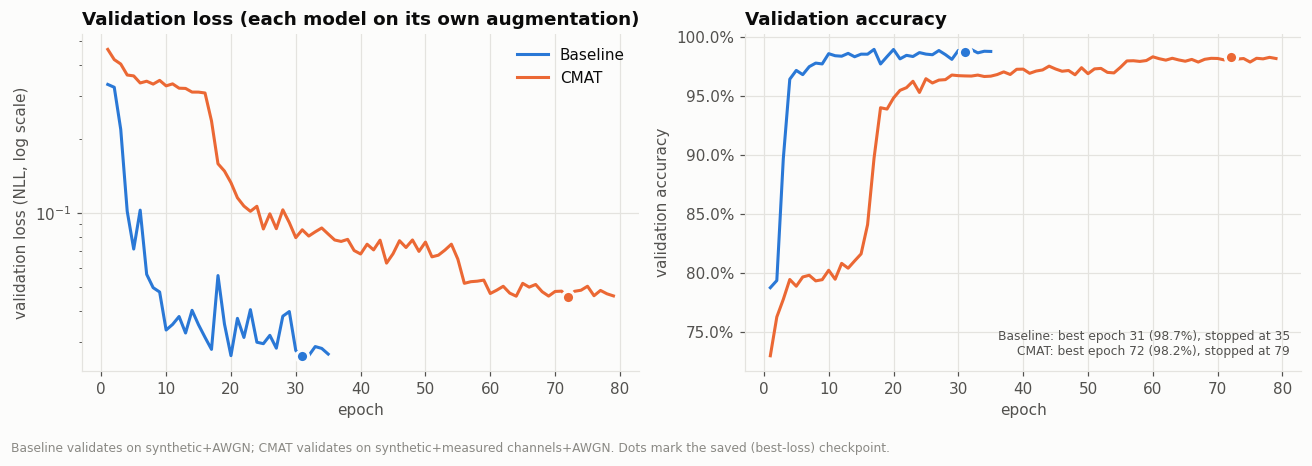

In [3]:
def load_history(run):
    h = os.path.join(ROOT, 'checkpoints/hcro', run, 'history.json')
    if os.path.exists(h):
        return pd.DataFrame(json.load(open(h)))
    # fallback: parse the training log
    txt = open(os.path.join(ROOT, 'logs', run + '.log')).read()
    tr = [float(v) / 100 for v in re.findall(r'Train Error: \n Accuracy: ([\d.]+)%', txt)]
    va = re.findall(r'Test Error: \n Accuracy: ([\d.]+)%, Avg loss: ([\d.]+)', txt)
    n = min(len(tr), len(va))
    return pd.DataFrame({'epoch': np.arange(1, n + 1), 'train_acc': tr[:n],
                         'val_acc': [float(a) / 100 for a, _ in va[:n]], 'val_loss': [float(l) for _, l in va[:n]]})

HIST = {k: load_history(v) for k, v in MODELS.items()}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
notes = []
for k, h in HIST.items():
    best = h.loc[h.val_loss.idxmin()]
    axes[0].plot(h.epoch, h.val_loss, color=COLORS[k], label=k)
    axes[0].plot(best.epoch, best.val_loss, 'o', ms=8, color=COLORS[k], mec=SURFACE, mew=2)
    axes[1].plot(h.epoch, h.val_acc, color=COLORS[k], label=k)
    axes[1].plot(best.epoch, best.val_acc, 'o', ms=8, color=COLORS[k], mec=SURFACE, mew=2)
    notes.append(f'{k}: best epoch {int(best.epoch)} ({best.val_acc:.1%}), stopped at {int(h.epoch.max())}')
axes[1].text(0.98, 0.04, '\n'.join(notes), transform=axes[1].transAxes, ha='right', va='bottom', fontsize=8, color=INK2)
axes[0].set(yscale='log', xlabel='epoch', ylabel='validation loss (NLL, log scale)',
            title='Validation loss (each model on its own augmentation)')
axes[1].set(xlabel='epoch', ylabel='validation accuracy', title='Validation accuracy')
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
axes[0].legend(loc='upper right')
fig.text(0.01, -0.04, 'Baseline validates on synthetic+AWGN; CMAT validates on synthetic+measured channels+AWGN. '
         'Dots mark the saved (best-loss) checkpoint.', fontsize=8, color=MUTED)
fig.tight_layout(); save(fig, '1_training_curves'); plt.show()

## 2. Headline: synthetic validation vs real-world accuracy

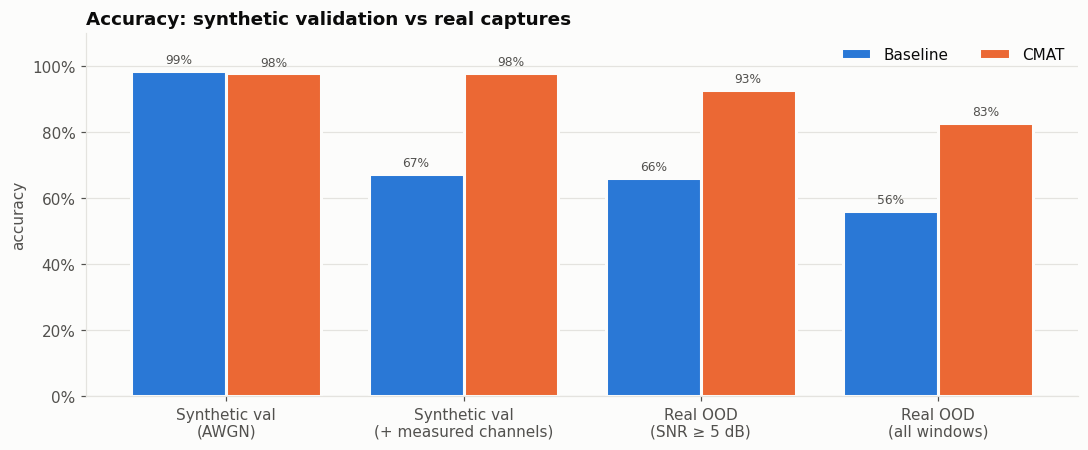

,Baseline,CMAT
Synthetic val (AWGN),98.5%,97.8%
Synthetic val (+ measured channels),67.2%,97.9%
Real OOD (SNR ≥ 5 dB),66.2%,92.9%
Real OOD (all windows),56.0%,82.9%
Real OOD balanced acc (SNR ≥ 5 dB),64.8%,93.0%
best epoch,31.0,72.0


In [4]:
metrics = {'Synthetic val\n(AWGN)': 'val_awgn', 'Synthetic val\n(+ measured channels)': 'val_cmat',
           f'Real OOD\n(SNR \u2265 {SNR_MIN:g} dB)': 'real_snr_ge_5dB', 'Real OOD\n(all windows)': 'real_all'}
vals = {k: {g: RES[v][m]['acc'] for g, m in metrics.items()} for k, v in MODELS.items()}
fig, ax = plt.subplots(figsize=(10, 4.2))
grouped_bars(ax, list(metrics), list(MODELS), vals)
ax.set_ylim(0, 1.1); ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_ylabel('accuracy'); ax.set_title('Accuracy: synthetic validation vs real captures')
ax.legend(loc='upper right', ncol=2)
fig.tight_layout(); save(fig, '2_headline'); plt.show()

summary = pd.DataFrame({k: {**{g.replace(chr(10), ' '): RES[v][m]['acc'] for g, m in metrics.items()},
                            f'Real OOD balanced acc (SNR \u2265 {SNR_MIN:g} dB)': RES[v]['real_snr_ge_5dB']['balanced_acc'],
                            'best epoch': RES[v].get('best_epoch')} for k, v in MODELS.items()})
summary.style.format(lambda x: f'{x:.1%}' if isinstance(x, float) and x <= 1 else x)

## 3. Per-class accuracy on real captures

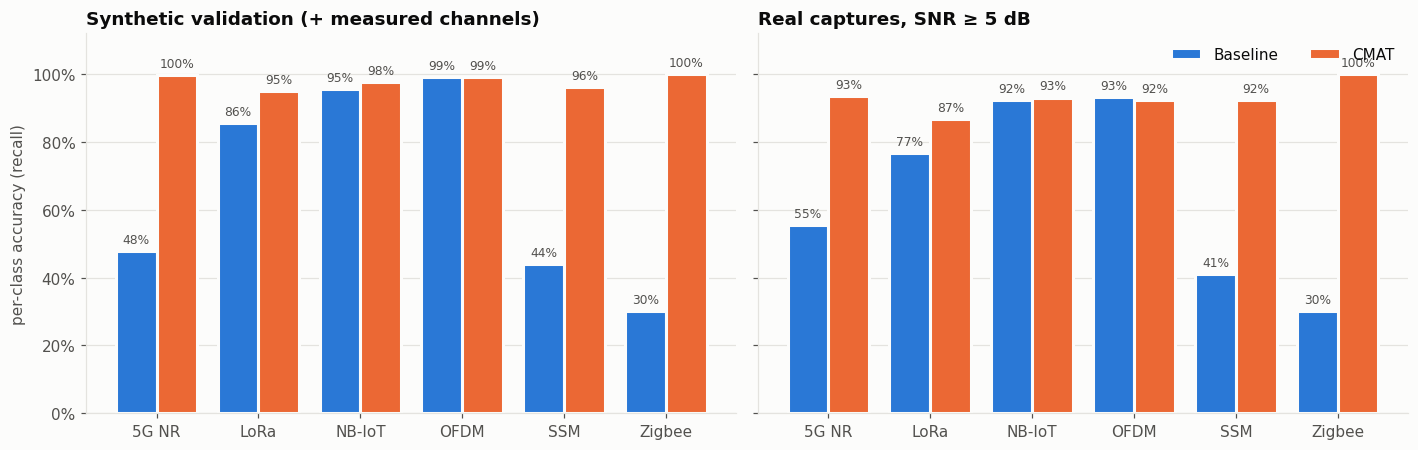

In [5]:
def per_class_acc(P, mask):
    y, p = P['y'][mask], P['p'][mask]
    return {CLASS_LABEL[c]: float((p[y == i] == i).mean()) for i, c in enumerate(CLASSES)}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, (title, key) in zip(axes, [('Synthetic validation (+ measured channels)', 'val_cmat'),
                                   (f'Real captures, SNR \u2265 {SNR_MIN:g} dB', 'real')]):
    if key == 'real':
        vals = {k: per_class_acc(P, P['snr_db'] >= SNR_MIN) for k, P in PRED.items()}
    else:
        vals = {k: {CLASS_LABEL[c]: RES[v][key]['per_class'][c] for c in CLASSES} for k, v in MODELS.items()}
    grouped_bars(ax, [CLASS_LABEL[c] for c in CLASSES], list(MODELS), vals)
    ax.set_title(title); ax.set_ylim(0, 1.12)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
axes[0].set_ylabel('per-class accuracy (recall)'); axes[1].legend(loc='upper right', ncol=2)
fig.tight_layout(); save(fig, '3_per_class'); plt.show()

## 4. Confusion matrices (row-normalised: true class -> predicted class)

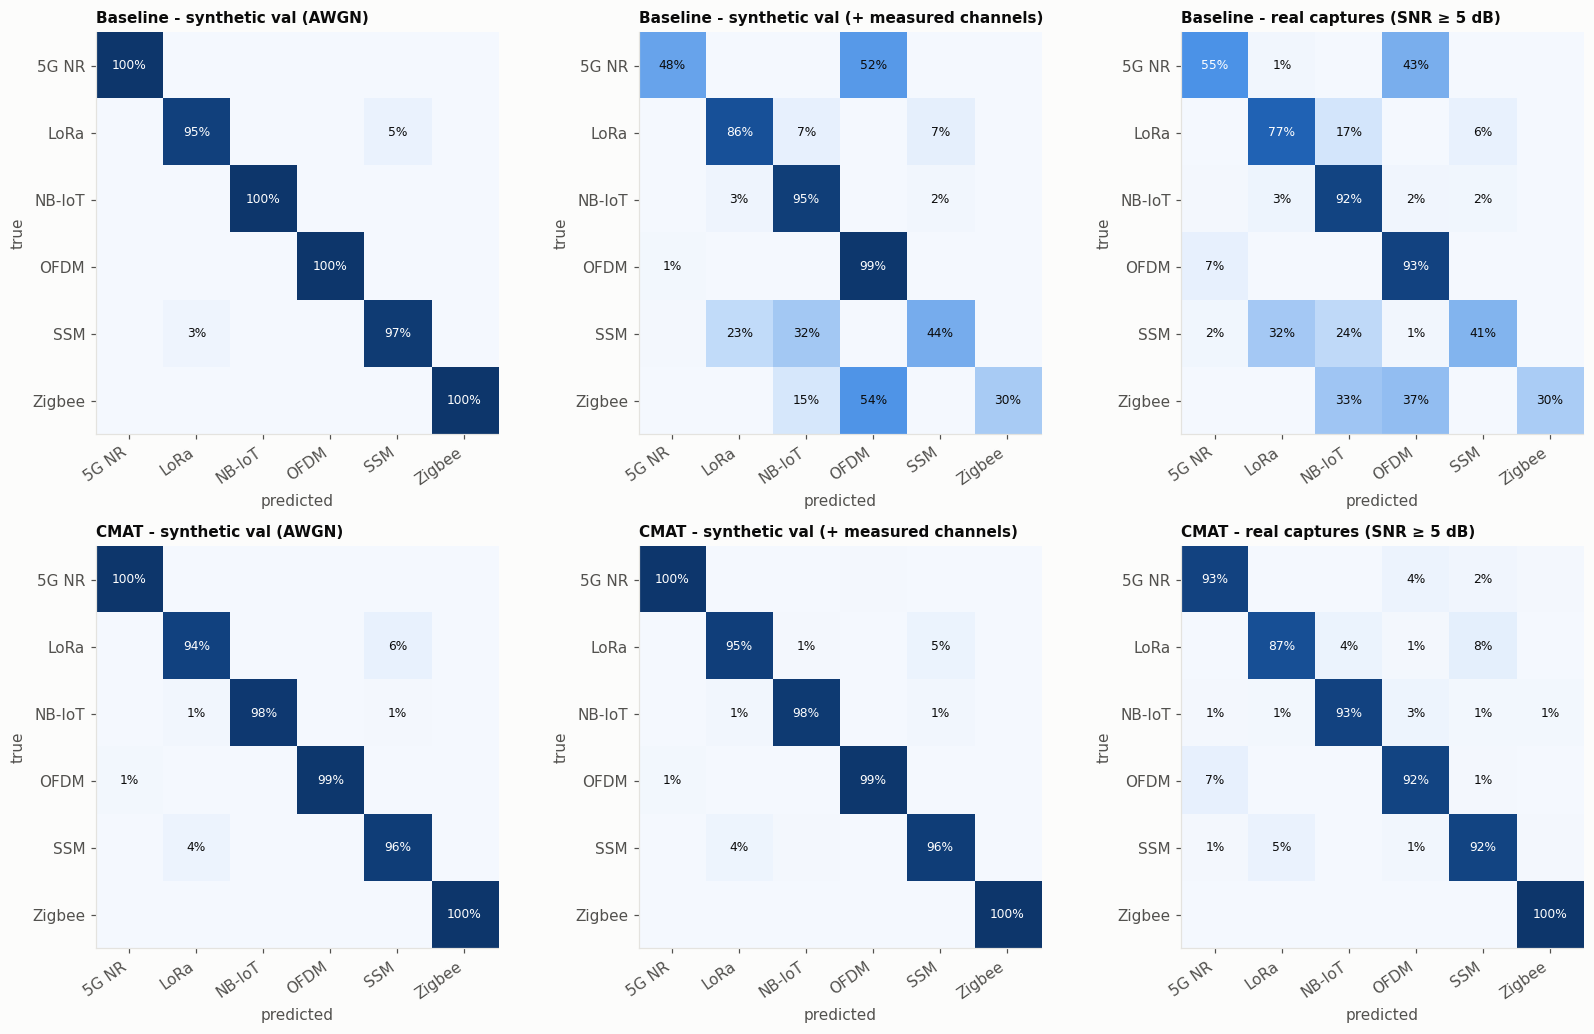

In [6]:
def conf(y, p):
    cm = np.zeros((len(CLASSES), len(CLASSES)))
    np.add.at(cm, (y, p), 1)
    return cm / np.maximum(cm.sum(1, keepdims=True), 1)

def plot_cm(ax, cm, title):
    ax.imshow(cm, cmap=SEQ_BLUE, vmin=0, vmax=1)
    labels = [CLASS_LABEL[c] for c in CLASSES]
    ax.set_xticks(range(len(labels)), labels, rotation=35, ha='right'); ax.set_yticks(range(len(labels)), labels)
    ax.grid(False); ax.set_title(title, fontsize=10)
    for i in range(len(labels)):
        for j in range(len(labels)):
            if cm[i, j] >= 0.005:
                ax.text(j, i, f'{cm[i, j]:.0%}', ha='center', va='center', fontsize=8,
                        color='#ffffff' if cm[i, j] > 0.55 else INK)
    ax.set_xlabel('predicted'); ax.set_ylabel('true')

fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
for r, (k, P) in enumerate(PRED.items()):
    plot_cm(axes[r, 0], conf(P['val_awgn_y'], P['val_awgn_p']), f'{k} - synthetic val (AWGN)')
    plot_cm(axes[r, 1], conf(P['val_cmat_y'], P['val_cmat_p']), f'{k} - synthetic val (+ measured channels)')
    m = P['snr_db'] >= SNR_MIN
    plot_cm(axes[r, 2], conf(P['y'][m], P['p'][m]), f'{k} - real captures (SNR \u2265 {SNR_MIN:g} dB)')
fig.tight_layout(); save(fig, '4_confusion'); plt.show()

## 5. Real-world accuracy vs wideband SNR

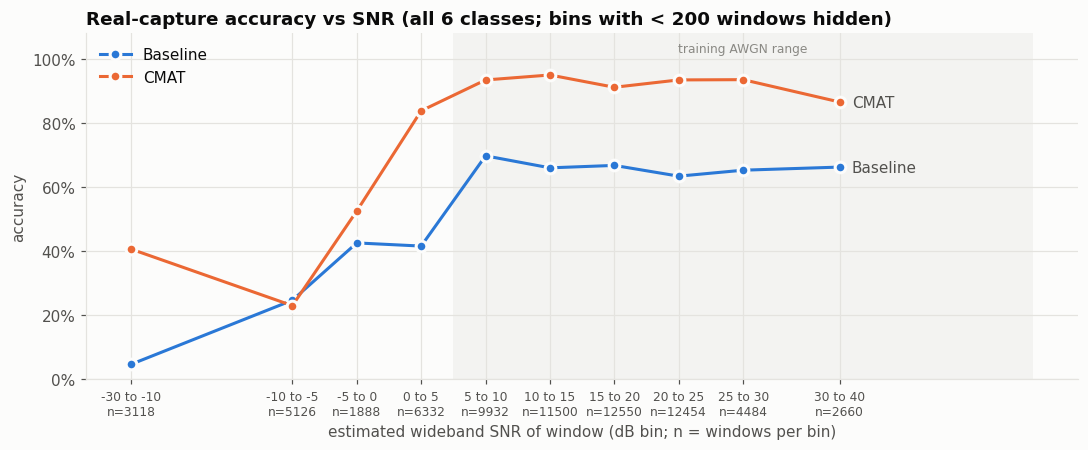

In [7]:
edges = np.array([-30, -10, -5, 0, 5, 10, 15, 20, 25, 30, 40])
centers = (edges[:-1] + edges[1:]) / 2
fig, ax = plt.subplots(figsize=(10, 4.2))
for k, P in PRED.items():
    acc, n = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (P['snr_db'] >= lo) & (P['snr_db'] < hi)
        n.append(m.sum()); acc.append((P['y'][m] == P['p'][m]).mean() if m.sum() >= 200 else np.nan)
    ax.plot(centers, acc, '-o', color=COLORS[k], ms=7, mec=SURFACE, mew=2, label=k)
    last = np.where(~np.isnan(acc))[0][-1]
    ax.annotate(k, (centers[last], acc[last]), xytext=(8, 0), textcoords='offset points', va='center', color=INK2)
ax.set_xticks(centers, [f'{lo:g} to {hi:g}\nn={nn}' for lo, hi, nn in zip(edges[:-1], edges[1:], n)], fontsize=8)
ax.axvspan(*SNR_TRAIN_RANGE, color=GRID, alpha=0.35, lw=0)
ax.text(np.mean(SNR_TRAIN_RANGE), 1.02, 'training AWGN range', ha='center', fontsize=8, color=MUTED)
ax.set(xlabel='estimated wideband SNR of window (dB bin; n = windows per bin)', ylabel='accuracy', ylim=(0, 1.08),
       title='Real-capture accuracy vs SNR (all 6 classes; bins with < 200 windows hidden)')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0)); ax.legend(loc='upper left')
fig.tight_layout(); save(fig, '5_acc_vs_snr'); plt.show()

## 6. Per-capture and per-condition accuracy

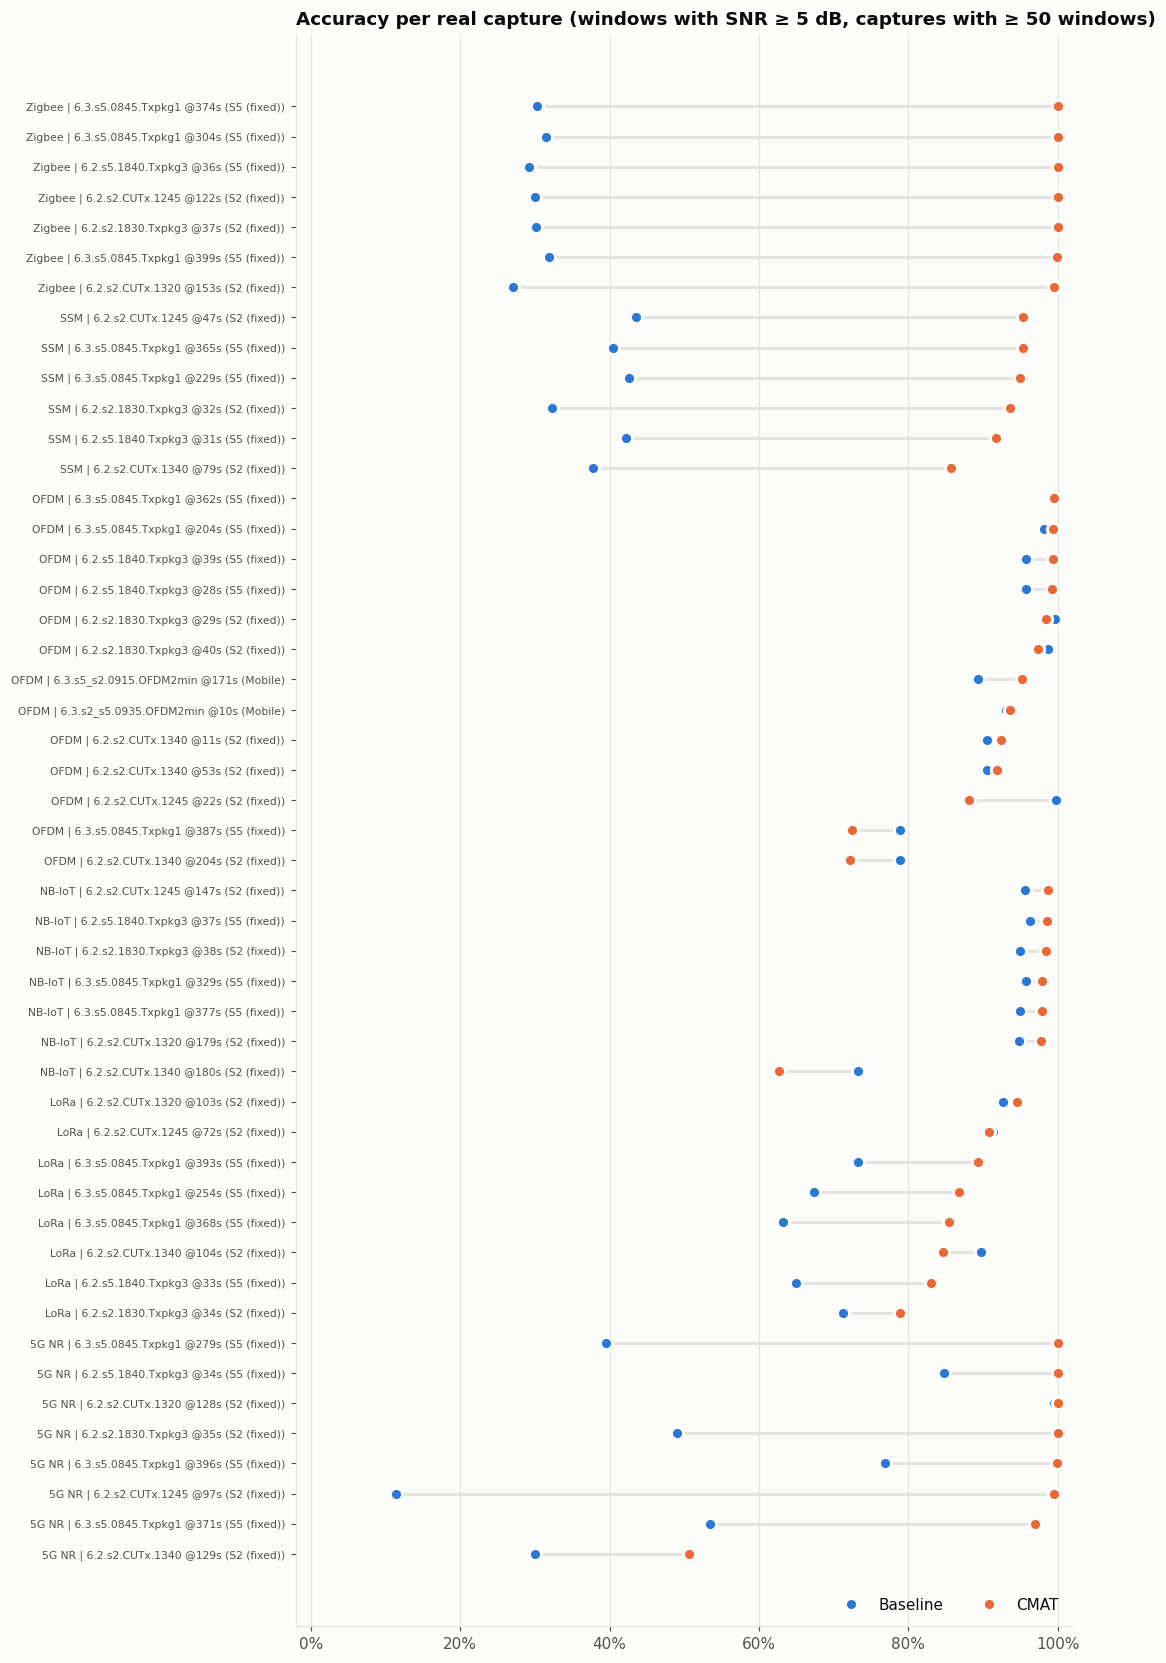

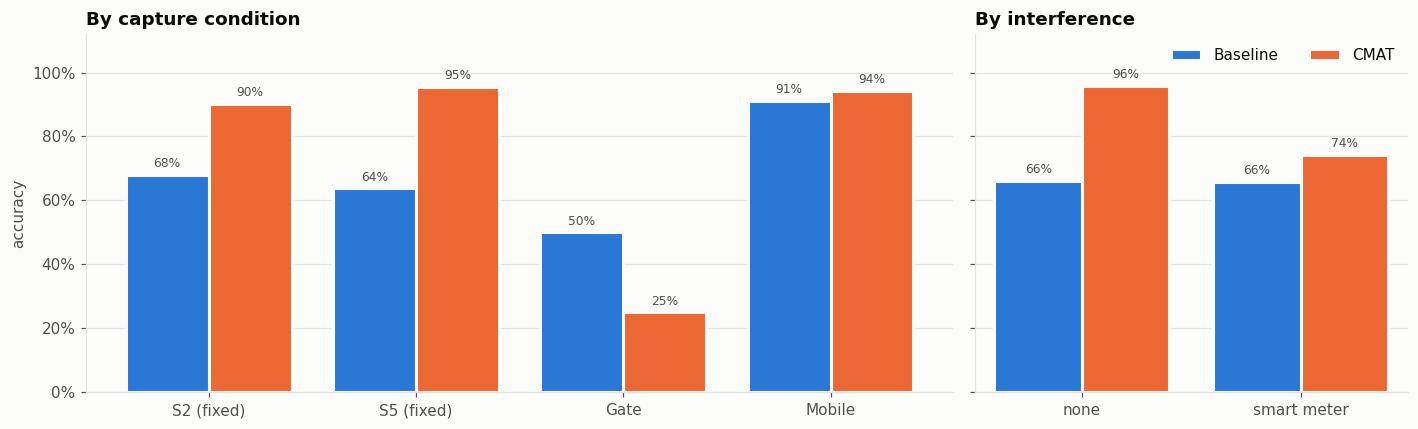

In [8]:
meta = {e['file_name']: e for f in glob.glob(f'{META_ROOT}/*/metadata.json') for e in json.load(open(f))}
def condition(fn):
    loc = meta[fn]['source_location']
    if 'OFDM2min' in fn or 'driving' in loc: return 'Mobile'
    if loc.startswith('Gate'): return 'Gate'
    return 'S2 (fixed)' if 'S2' in loc.split('/')[0] or loc.startswith('S2') else 'S5 (fixed)'

rows = []
for k, P in PRED.items():
    for fn in np.unique(P['fname']):
        m = (P['fname'] == fn) & (P['snr_db'] >= SNR_MIN)
        if m.sum() < 50: continue
        rows.append({'model': k, 'file': fn, 'class': CLASS_LABEL[meta[fn]['signal_type']], 'n': int(m.sum()),
                     'acc': float((P['y'][m] == P['p'][m]).mean()), 'condition': condition(fn),
                     'interference': meta[fn]['interference'], 'median_snr_db': float(np.median(P['snr_db'][m]))})
per_file = pd.DataFrame(rows)

# dumbbell: one row per capture, baseline -> CMAT
wide = per_file.pivot_table(index=['class', 'file', 'condition'], columns='model', values='acc').reset_index()
wide = wide.sort_values(['class', 'CMAT'])
fig, ax = plt.subplots(figsize=(10, 0.28 * len(wide) + 1.5))
yy = np.arange(len(wide))
ax.hlines(yy, wide.Baseline, wide.CMAT, color=GRID, lw=2)
for k in MODELS:
    ax.plot(wide[k], yy, 'o', ms=8, color=COLORS[k], mec=SURFACE, mew=2, label=k)
def short_name(fn):  # '6.2.s2.CUTx.1245.ssm.47.211-67.282.bin' -> '6.2.s2.CUTx.1245 @47s'
    head, tail = fn[:-4].split('.' + meta[fn]['signal_type'] + '.')
    return f"{head} @{tail.split('.')[0]}s"
ax.set_yticks(yy, [f'{c} | {short_name(f)} ({cond})' for c, f, cond in zip(wide['class'], wide.file, wide.condition)],
              fontsize=7)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0)); ax.set_xlim(-0.02, 1.02)
ax.grid(axis='y', visible=False); ax.legend(loc='lower right', ncol=2)
ax.set_title(f'Accuracy per real capture (windows with SNR \u2265 {SNR_MIN:g} dB, captures with \u2265 50 windows)')
fig.tight_layout(); save(fig, '6a_per_capture'); plt.show()

def pooled(df_mask_key):
    out = {}
    for k, P in PRED.items():
        conds = np.array([condition(f) if df_mask_key == 'condition' else meta[f]['interference'] for f in P['fname']])
        m0 = P['snr_db'] >= SNR_MIN
        out[k] = {g: float((P['y'][m0 & (conds == g)] == P['p'][m0 & (conds == g)]).mean()) for g in np.unique(conds[m0])}
    return out

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True, gridspec_kw={'width_ratios': [2, 1]})
v = pooled('condition'); grouped_bars(axes[0], [g for g in ['S2 (fixed)', 'S5 (fixed)', 'Gate', 'Mobile'] if g in v['Baseline']], list(MODELS), v)
axes[0].set_title('By capture condition'); axes[0].set_ylabel('accuracy')
v = pooled('interference'); grouped_bars(axes[1], sorted(v['Baseline']), list(MODELS), v)
axes[1].set_title('By interference'); axes[1].legend(loc='upper right', ncol=2)
for ax in axes:
    ax.set_ylim(0, 1.12); ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
fig.tight_layout(); save(fig, '6b_by_condition'); plt.show()

## 7. Hopped SSM (no synthetic counterpart)
Full-band hopping SSM-like captures are not a training class; here is where each model puts them
(SNR >= 5 dB windows). Ideally they land on SSM.

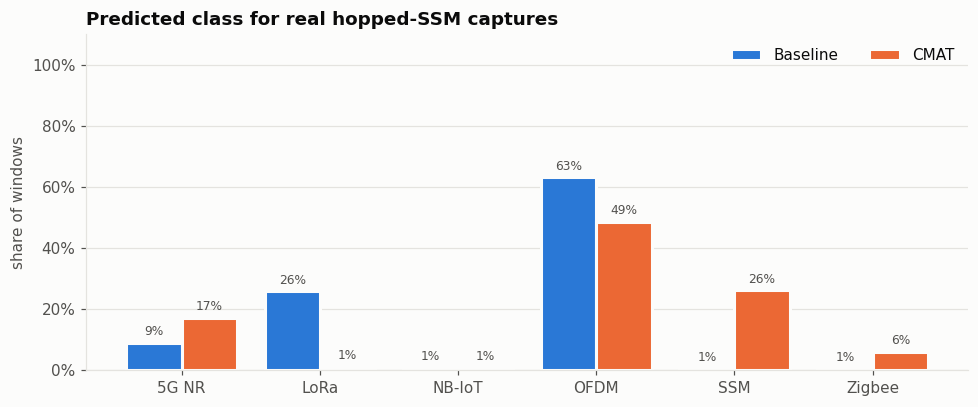

In [9]:
vals = {}
for k, P in PRED.items():
    m = P['hop_snr_db'] >= SNR_MIN
    vals[k] = {CLASS_LABEL[c]: float((P['hop_p'][m] == i).mean()) for i, c in enumerate(CLASSES)}
fig, ax = plt.subplots(figsize=(9, 3.8))
grouped_bars(ax, [CLASS_LABEL[c] for c in CLASSES], list(MODELS), vals)
ax.set(ylim=(0, 1.1), ylabel='share of windows', title='Predicted class for real hopped-SSM captures')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0)); ax.legend(loc='upper right', ncol=2)
fig.tight_layout(); save(fig, '7_hoppedssm'); plt.show()

## 8. Effect of the two fixes (and of the training SNR range, in the SNR 5-50 dB variant)
1. **SSM sample rate**: `SSM_peaknorm.bin` is stored at 1 MS/s (16 samples/symbol) but was first treated as
   30.72 MS/s, making the synthetic SSM ~30x too wide. It is now resampled to 30.72 MS/s.
2. **CMAT channel shift**: `apply_channel_via_fft` selected the centre 1024 bins one bin off
   (`start1024 = (1201-1024)//2 + 1`), shifting every channel-augmented sample by -30 kHz. Harmless for
   wideband classes, but equal to the whole bandwidth of SSM, so CMAT learned SSM at the wrong frequency.

Real-capture accuracy (SNR >= 5 dB) at each stage. The first CMAT stage was evaluated at epoch 77 of a run stopped early.

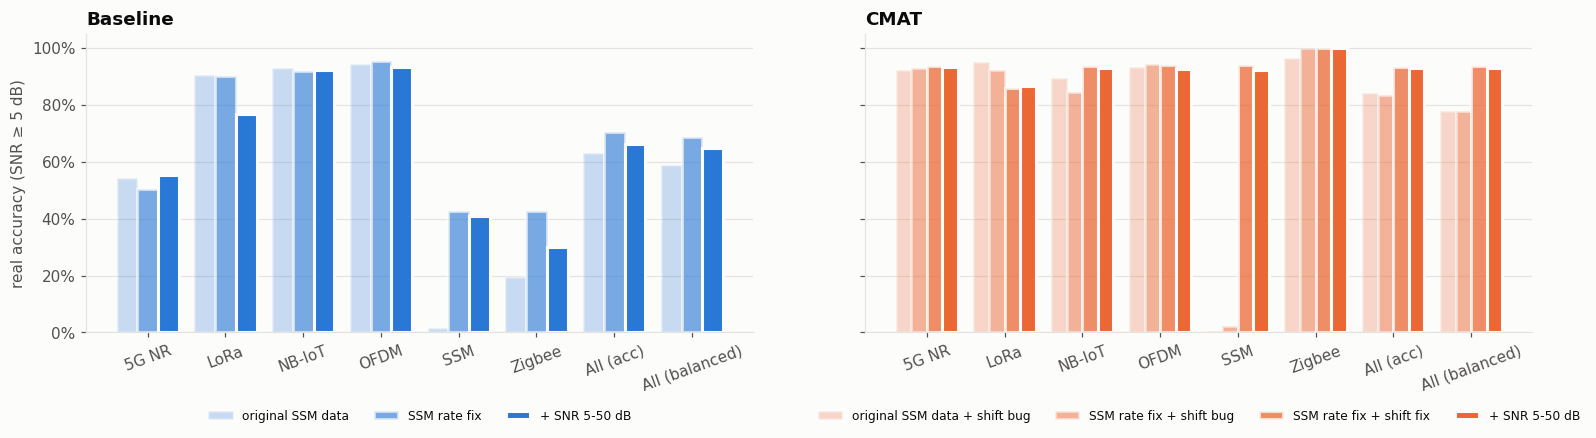

In [10]:
if STAGES:
    groups = [CLASS_LABEL[c] for c in CLASSES] + ['All (acc)', 'All (balanced)']
    rows = {}
    fig, axes = plt.subplots(1, len(STAGES), figsize=(15, 4.2), sharey=True)
    for ax, (k, stages) in zip(np.atleast_1d(axes), STAGES.items()):
        n = len(stages); w = 0.8 / n; x = np.arange(len(groups))
        for i, (label, d, run) in enumerate(stages):
            r = json.load(open(os.path.join(d, 'results.json')))[run]['real_snr_ge_5dB']
            v = [r['per_class'][c] for c in CLASSES] + [r['acc'], r['balanced_acc']]
            rows[(k, label)] = dict(zip(groups, v))
            ax.bar(x + (i - (n - 1) / 2) * w, v, w, color=COLORS[k], alpha=np.linspace(0.25, 1.0, n)[i],
                   label=label, edgecolor=SURFACE, linewidth=2)
        ax.set_xticks(x, groups, rotation=20); ax.grid(axis='x', visible=False); ax.set_title(k)
        ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=len(stages), fontsize=8); ax.set_ylim(0, 1.05)
        ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    np.atleast_1d(axes)[0].set_ylabel(f'real accuracy (SNR \u2265 {SNR_MIN:g} dB)')
    fig.tight_layout(); save(fig, '8_fixes'); plt.show()
    display(pd.DataFrame(rows).T.style.format('{:.1%}'))

## 9. Tables

In [11]:
tbl = pd.DataFrame({k: {**{f'val_awgn {CLASS_LABEL[c]}': RES[v]['val_awgn']['per_class'][c] for c in CLASSES},
                        **{f'real \u22655dB {CLASS_LABEL[c]}': RES[v]['real_snr_ge_5dB']['per_class'][c] for c in CLASSES}}
                    for k, v in MODELS.items()})
display(tbl.style.format('{:.1%}'))
display(per_file.pivot_table(index=['class', 'condition', 'file'], columns='model', values='acc').style.format('{:.1%}'))

,Baseline,CMAT
val_awgn 5G NR,99.9%,100.0%
val_awgn LoRa,94.5%,93.7%
val_awgn NB-IoT,99.7%,98.1%
val_awgn OFDM,99.9%,98.9%
val_awgn SSM,97.1%,96.0%
val_awgn Zigbee,100.0%,100.0%
real ≥5dB 5G NR,55.4%,93.4%
real ≥5dB LoRa,76.7%,86.7%
real ≥5dB NB-IoT,92.2%,93.0%
real ≥5dB OFDM,93.2%,92.4%
